# Dynamical X-ray Scattering

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dschick/udkm1Dsim/blob/develop/examples/08-xray_diffraction/02-dynamical_xray.ipynb)

In this example the static and transient X-ray diffraction of a thin SrRuO$_3$ film on a SrTiO$_3$ substrate after an optical excitation is calculated by the dynamical X-ray scattering formalism of {py:class}`XrayDyn <udkm1Dsim.simulations.scattering.dynamical.XrayDyn>`, see the [scattering overview](#example_scattering_overview) for all formalisms.

:::{admonition} Reference {cite}`alsnielsen2011`
:class: seealso
J. Als-Nielsen and D. McMorrow, *Elements of Modern X-ray Physics*, 2nd ed., [Wiley (2011)](https://doi.org/10.1002/9781119998365)
:::

## Setup

Do all necessary imports and settings.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

try:
    import udkm1Dsim as ud
except ImportError:
    %pip install udkm1Dsim[parallel]
    import udkm1Dsim as ud

u = ud.u  # import the pint unit registry from udkm1Dsim
u.setup_matplotlib()  # use matplotlib with pint units

%matplotlib inline

## Structure

Refer to the [structure example](#example_structure) for more details.

In [2]:
O = ud.Atom("O")
Ti = ud.Atom("Ti")
Sr = ud.Atom("Sr")
Ru = ud.Atom("Ru")
Pb = ud.Atom("Pb")
Zr = ud.Atom("Zr")

In [3]:
# c-axis lattice constants of the two layers
c_STO_sub = 3.905 * u.angstrom
c_SRO = 3.94897 * u.angstrom

# SRO layer
SRO = ud.UnitCell(
    "SRO",
    "Strontium Ruthenate",
    lattice=ud.LatticeParameters(a_axis=c_STO_sub, b_axis=c_STO_sub, c_axis=c_SRO),
    thermal=ud.ThermalParameters(
        therm_cond=5.72 * u.W / (u.m * u.K),
        lin_therm_exp=1.03e-5,
        heat_capacity="455.2 + 0.112*T - 2.1935e6/T**2",  # (J/kg K)
        deb_wal_fac=0,
    ),
    elastic=ud.ElasticParameters(sound_vel=6.312 * u.nm / u.ps),
    optical=ud.OpticalParameters(dielectric=ud.Dispersion.from_ref_index(2.44 + 4.32j)),
)
SRO.add_atom(O, 0)
SRO.add_atom(Sr, 0)
SRO.add_atom(O, 0.5)
SRO.add_atom(O, 0.5)
SRO.add_atom(Ru, 0.5)

# STO substrate
STO_sub = ud.UnitCell(
    "STOsub",
    "Strontium Titanate Substrate",
    lattice=ud.LatticeParameters(c_axis=c_STO_sub),  # a- and b-axis default to the c-axis
    thermal=ud.ThermalParameters(
        therm_cond=12 * u.W / (u.m * u.K),
        lin_therm_exp=1e-5,
        heat_capacity="733.73 + 0.0248*T - 6.531e6/T**2",  # (J/kg K)
        deb_wal_fac=0,
    ),
    elastic=ud.ElasticParameters(sound_vel=7.800 * u.nm / u.ps),
    optical=ud.OpticalParameters(dielectric=ud.Dispersion.from_ref_index(2.1 + 0j)),
)
STO_sub.add_atom(O, 0)
STO_sub.add_atom(Sr, 0)
STO_sub.add_atom(O, 0.5)
STO_sub.add_atom(O, 0.5)
STO_sub.add_atom(Ti, 0.5)

In [4]:
S = ud.Structure("Single Layer")
S.add_sub_structure(SRO, 200)  # add 200 layers of SRO to sample
S.add_sub_structure(STO_sub, 1000)  # add 1000 layers of dynamic STO substrate

# add 1000000 layers of static STO substrate
# optically the substrate is also semi-infinite
S.add_substrate(STO_sub, 1000000)

## Heat

Refer to the [excitation & NTM example](#example_excitation_NTM) for more details.

In [5]:
h = ud.Heat(S, True)

h.save_data = False
h.disp_messages = True

h.excitation = {
    "fluence": [35] * u.mJ / u.cm**2,
    "delay_pump": [0] * u.ps,
    "pulse_width": [0] * u.ps,
    "multilayer_absorption": True,
    "wavelength": 800 * u.nm,
    "theta": 45 * u.deg,
}

# temporal and spatial grid
delays = np.r_[-5:40:0.1] * u.ps
_, _, distances = S.get_distances_of_layers()

In [6]:
res_temp = h.get_temp_map(delays, 300 * u.K)

Surface incidence fluence scaled by factor 0.7071 due to incidence angle theta=45.00 deg
Absorption profile is calculated by multilayer formalism with p-polarization.
Total reflectivity of 58.5 % and transmission of 0.4 %.
Elapsed time for _temperature_after_delta_excitation_: 0.161512 s
Elapsed time for _temp_map_: 0.183509 s


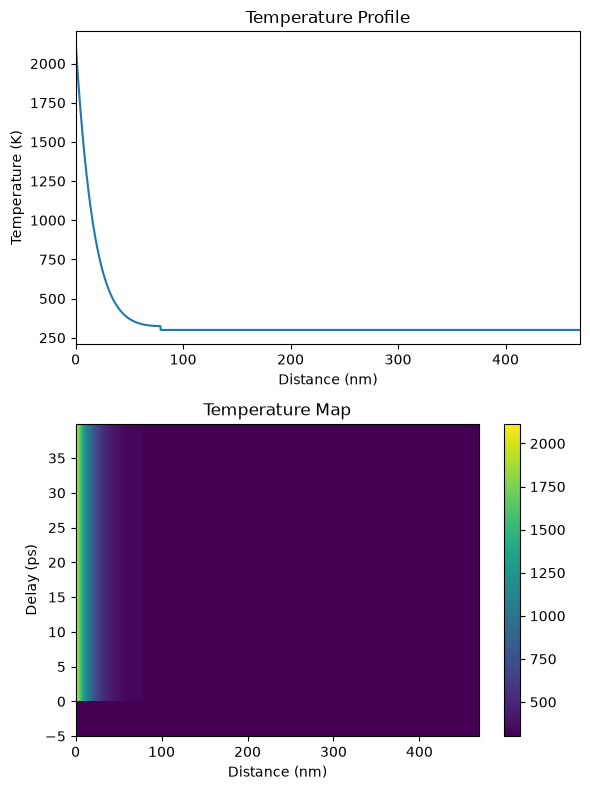

In [7]:
plt.figure(figsize=[6, 8])
plt.subplot(2, 1, 1)
plt.plot(res_temp.quantity("distances", "nm"), res_temp.temp_map[101, :])
plt.xlim([0, res_temp.quantity("distances", "nm")[-1]])
plt.xlabel("Distance (nm)")
plt.ylabel("Temperature (K)")
plt.title("Temperature Profile")

plt.subplot(2, 1, 2)
plt.pcolormesh(
    res_temp.quantity("distances", "nm"),
    res_temp.quantity("delays", "ps"),
    res_temp.temp_map,
    shading="auto",
)
plt.colorbar()
plt.xlabel("Distance (nm)")
plt.ylabel("Delay (ps)")
plt.title("Temperature Map")

plt.tight_layout()
plt.show()

## Numerical Phonons

Refer to the [strain pulse example](#example_strain_pulses) for more details.

In [8]:
p = ud.PhononNum(S, True)
p.save_data = False
p.disp_messages = True

In [9]:
res_strain = p.get_strain_map(delays, res_temp)

Calculating linear thermal expansion ...
Calculating coherent dynamics with ODE solver ...


0it [00:00, ?it/s]

Elapsed time for _strain_map_: 0.563827 s


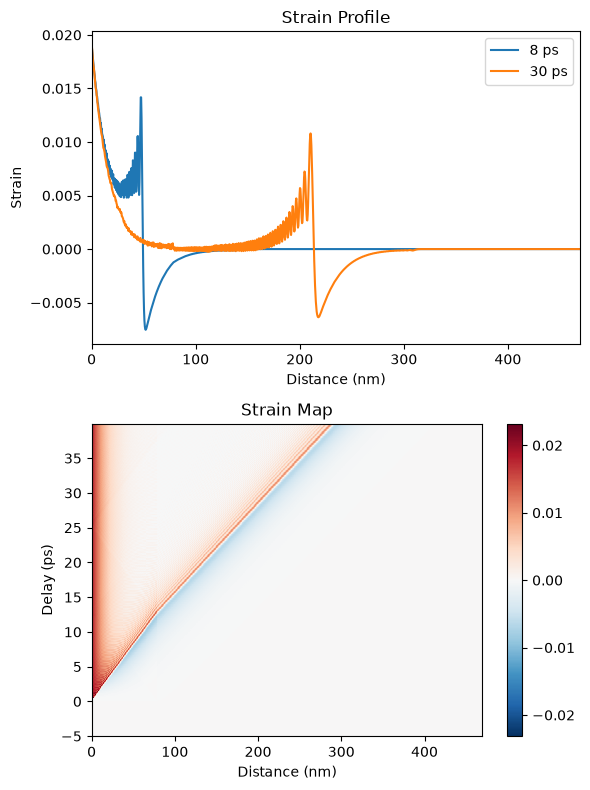

In [10]:
plt.figure(figsize=[6, 8])
plt.subplot(2, 1, 1)
plt.plot(
    res_strain.quantity("distances", "nm"),
    res_strain.strain_map[130, :],
    label=np.round(res_strain.quantity("delays", "ps")[130]),
)
plt.plot(
    res_strain.quantity("distances", "nm"),
    res_strain.strain_map[350, :],
    label=np.round(res_strain.quantity("delays", "ps")[350]),
)
plt.xlim([0, res_strain.quantity("distances", "nm")[-1]])
plt.xlabel("Distance (nm)")
plt.ylabel("Strain")
plt.legend()
plt.title("Strain Profile")

plt.subplot(2, 1, 2)
plt.pcolormesh(
    res_strain.quantity("distances", "nm"),
    res_strain.quantity("delays", "ps"),
    res_strain.strain_map,
    cmap="RdBu_r",
    vmin=-np.max(res_strain.strain_map),
    vmax=np.max(res_strain.strain_map),
    shading="auto",
)
plt.colorbar()
plt.xlabel("Distance (nm)")
plt.ylabel("Delay (ps)")
plt.title("Strain Map")

plt.tight_layout()
plt.show()

## Dynamical X-ray Simulation

The {py:class}`XrayDyn <udkm1Dsim.simulations.scattering.dynamical.XrayDyn>` simulation is initialized as all other simulations, see the [scattering overview](#example_scattering_overview) for its experiment parameters and polarizations.

In [11]:
dyn = ud.XrayDyn(S, True)
dyn.disp_messages = True
dyn.save_data = False

## Homogeneous X-ray scattering

For the case of homogeneously strained samples, the dynamical X-ray scattering simulations can be greatly simplified, which saves a lot of computational time.

### $q_z$-scan

The reflectivity has a first dimension for the photon energies and a second for the scattering vectors $q_z$, see the experiment parameters in the [scattering overview](#example_scattering_overview).

In [12]:
dyn.energy = np.r_[5000, 8047] * u.eV  # set two photon energies
dyn.qz = np.r_[3.1:3.3:0.00001] / u.angstrom  # qz range

res_hom = dyn.homogeneous_reflectivity()  # this is the actual calculation

Calculating _homogeneous_reflectivity_ ...
Elapsed time for _homogeneous_reflectivity_: 1.912789 s


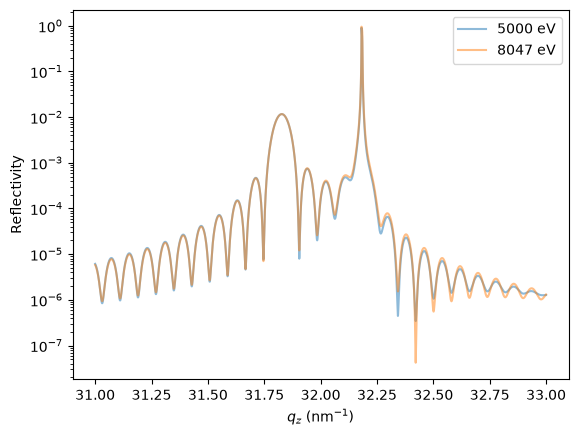

In [13]:
plt.figure()
plt.semilogy(
    res_hom.qz[0, :],
    res_hom.R[0, :],
    label=f"{res_hom.quantity('energy')[0]}",
    alpha=0.5,
)
plt.semilogy(
    res_hom.qz[1, :],
    res_hom.R[1, :],
    label=f"{res_hom.quantity('energy')[1]}",
    alpha=0.5,
)
plt.ylabel("Reflectivity")
plt.xlabel("$q_z$ (nm$^{-1}$)")
plt.legend()
plt.show()

Due to the very thick static `substrate` in the {py:class}`Structure <udkm1Dsim.structures.structure.Structure>` and the very small step width in `qz` also the Darwin width of the substrate Bragg peak is nicely resolvable. 

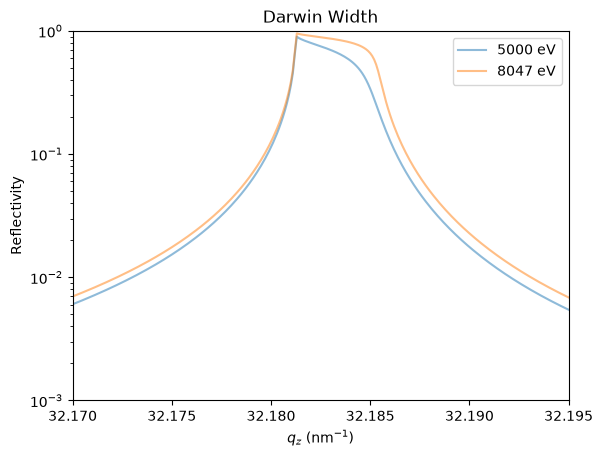

In [14]:
plt.figure()
plt.semilogy(
    res_hom.qz[0, :],
    res_hom.R[0, :],
    label=f"{res_hom.quantity('energy')[0]}",
    alpha=0.5,
)
plt.semilogy(
    res_hom.qz[1, :],
    res_hom.R[1, :],
    label=f"{res_hom.quantity('energy')[1]}",
    alpha=0.5,
)
plt.ylabel("Reflectivity")
plt.xlabel("$q_z$ (nm$^{-1}$)")
plt.xlim(32.17, 32.195)
plt.ylim(1e-3, 1)
plt.legend()
plt.title("Darwin Width")
plt.show()

### Post-Processing

All result can be convoluted with an arbitrary function handle, which e.g. mimics the instrumental resolution.

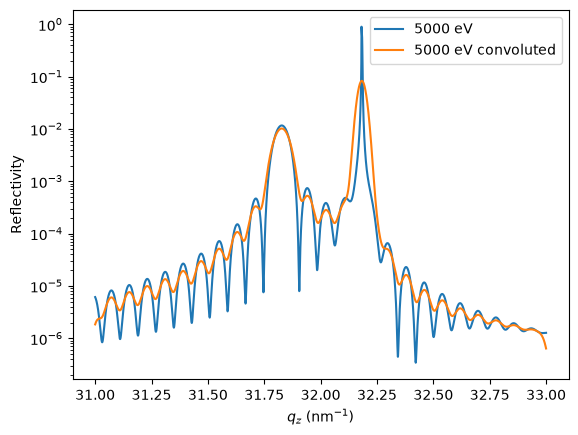

In [15]:
FWHM = 0.004 / 1e-10  # Angstrom
sigma = FWHM / 2.3548

handle = lambda x: np.exp(-(((x) / sigma) ** 2) / 2)
y_conv = dyn.conv_with_function(
    res_hom.R[0, :], res_hom.quantity("qz", "1/m").magnitude[0, :], handle
)

plt.figure()
plt.semilogy(res_hom.qz[0, :], res_hom.R[0, :], label=f"{res_hom.quantity('energy')[0]}")
plt.semilogy(res_hom.qz[0, :], y_conv, label=f"{res_hom.quantity('energy')[0]} convoluted")
plt.ylabel("Reflectivity")
plt.xlabel("$q_z$ (nm$^{-1}$)")
plt.legend()
plt.show()

### Energy-scan

Energy scans rely on the tabulated atomic form factors, which also include the energy ranges around the absorption edges.

Calculating _homogeneous_reflectivity_ ...
Elapsed time for _homogeneous_reflectivity_: 0.213960 s


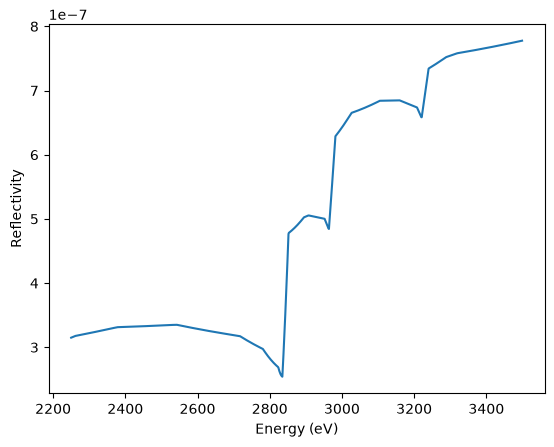

In [16]:
dyn.qz = np.r_[1.0] / u.angstrom  # qz range
dyn.energy = np.r_[2250:3500] * u.eV  # set the energy range

res_hom = dyn.homogeneous_reflectivity()  # this is the actual calculation

plt.figure()
plt.plot(res_hom.quantity("energy"), res_hom.R[:, 0])
plt.ylabel("Reflectivity")
plt.xlabel("Energy (eV)")
plt.show()

## Inhomogeneous X-ray scattering

The {py:meth}`inhomogeneous_reflectivity <udkm1Dsim.simulations.scattering.dynamical.XrayDyn.inhomogeneous_reflectivity>` method allows to calculate the transient X-ray reflectivity according to a `strain_map`.

The strains of the layers can be discretized by the `strain_vectors` to save computational time.

:::{versionadded} 2.3.0
The `strain_vectors` are optional, which allows to compare the computational speed of both approaches.
:::

Without `strain_vectors`, the reflectivity is calculated exactly for every {py:class}`UnitCell <udkm1Dsim.structures.layers.UnitCell>` and the exact values of the `strain_map`.

The SRO Bragg peak splits up into the peaks of the expanded part of the film and of its not yet strained part, while the expansion propagates through the film within about 13 ps, as discussed in detail by {cite:t}`schick2014`.

:::{admonition} Reference {cite}`schick2014`
:class: seealso
D. Schick, M. Herzog, A. Bojahr, W. Leitenberger, A. Hertwig, R. Shayduk, and M. Bargheer, *Ultrafast lattice response of photoexcited thin films studied by X-ray diffraction*, [Struct. Dyn. 1, 064501 (2014)](https://doi.org/10.1063/1.4901228)
:::

In [17]:
dyn.energy = np.r_[8047] * u.eV
dyn.qz = np.r_[3.1:3.3:0.001] / u.angstrom  # qz range

strain_vectors = p.calc_reduced_strains_per_unique_layer(res_strain)
res_seq = dyn.inhomogeneous_reflectivity(res_strain, strain_vectors, calc_type="sequential")

Calculating _inhomogeneous_reflectivity_dyn_ ...
Calculating _all_ref_trans_matrices_dyn_ ...
Calculate all _ref_trans_matrices_ ...
Elapsed time for _ref_trans_matrices_: 0.469858 s
Elapsed time for _all_ref_trans_matrices_dyn_: 0.472938 s


Progress:   0%|          | 0/450 [00:00<?, ?it/s]

Elapsed time for _inhomogeneous_reflectivity_dyn_: 16.512736 s


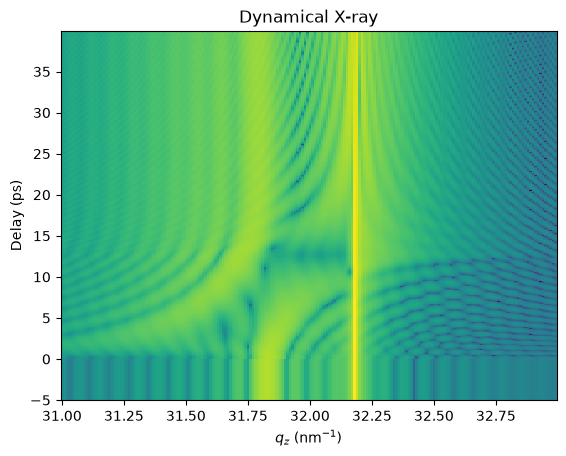

In [18]:
plt.figure()
plt.pcolormesh(
    res_seq.qz[0, :],
    res_seq.quantity("delays", "ps"),
    np.log10(res_seq.R[:, 0, :]),
    shading="auto",
)
plt.title("Dynamical X-ray")
plt.ylabel("Delay (ps)")
plt.xlabel("$q_z$ (nm$^{-1}$)")
plt.show()

The results can be convoluted again to mimic real experimental resolution:

In [19]:
R_seq_conv = np.zeros_like(res_seq.R)
for i in range(len(res_seq.delays)):
    R_seq_conv[i, 0, :] = dyn.conv_with_function(
        res_seq.R[i, 0, :], res_seq.quantity("qz", "1/m").magnitude[0, :], handle
    )

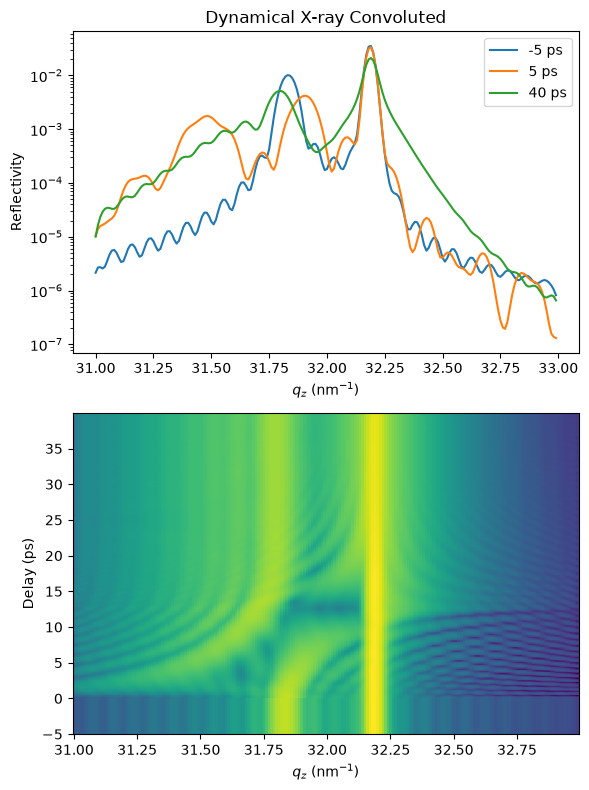

In [20]:
plt.figure(figsize=[6, 8])
plt.subplot(2, 1, 1)
plt.semilogy(
    res_seq.quantity("qz", "1/nm")[0, :],
    R_seq_conv[0, 0, :],
    label=np.round(res_seq.quantity("delays", "ps")[0]),
)
plt.semilogy(
    res_seq.quantity("qz", "1/nm")[0, :],
    R_seq_conv[100, 0, :],
    label=np.round(res_seq.quantity("delays", "ps")[100]),
)
plt.semilogy(
    res_seq.quantity("qz", "1/nm")[0, :],
    R_seq_conv[-1, 0, :],
    label=np.round(res_seq.quantity("delays", "ps")[-1]),
)

plt.xlabel("$q_z$ (nm$^{-1}$)")
plt.ylabel("Reflectivity")
plt.legend()
plt.title("Dynamical X-ray Convoluted")

plt.subplot(2, 1, 2)
plt.pcolormesh(
    res_seq.qz[0, :],
    res_seq.quantity("delays", "ps"),
    np.log10(R_seq_conv[:, 0, :]),
    shading="auto",
)
plt.ylabel("Delay (ps)")
plt.xlabel("$q_z$ (nm$^{-1}$)")

plt.tight_layout()
plt.show()

## Parallel Inhomogeneous X-ray Scattering

The delays can be calculated in parallel with [Dask](https://docs.dask.org/en/latest/), which requires the `parallel` option of the **udkm1Dsim** toolbox, e.g. by `pip install udkm1Dsim[parallel]`.

In [21]:
try:
    from dask.distributed import Client

    client = Client(threads_per_worker=1)  # one worker per CPU core
    res_par = dyn.inhomogeneous_reflectivity(
        res_strain, strain_vectors, calc_type="parallel", dask_client=client
    )
    client.close()
except ImportError:
    pass

Calculating _inhomogeneous_reflectivity_dyn_ ...
Calculating _all_ref_trans_matrices_dyn_ ...
Calculate all _ref_trans_matrices_ ...
Elapsed time for _ref_trans_matrices_: 0.603117 s
Elapsed time for _all_ref_trans_matrices_dyn_: 0.605777 s


Progress:   0%|          | 0/450 [00:00<?, ?it/s]

Elapsed time for _inhomogeneous_reflectivity_dyn_: 6.340262 s


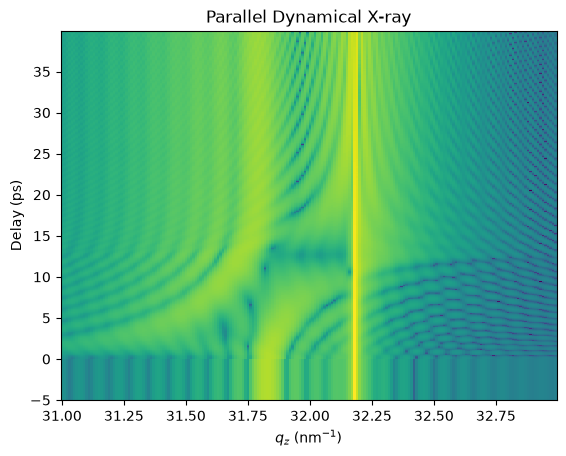

In [22]:
plt.figure()
plt.pcolormesh(
    res_par.qz[0, :],
    res_par.quantity("delays", "ps"),
    np.log10(res_par.R[:, 0, :]),
    shading="auto",
)
plt.title("Parallel Dynamical X-ray")
plt.ylabel("Delay (ps)")
plt.xlabel("$q_z$ (nm$^{-1}$)")
plt.show()